# BANK LOAN ANALYSIS REPORT

#### Import Libraries

In [2]:
import pandas as ps
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import plotly.express as px 

In [3]:
df = ps.read_excel("C:/Projects Data/Loan_Excel.xlsx")

In [7]:
df.head()

,id,address_state,application_type,emp_length,emp_title,grade,home_ownership,issue_date,last_credit_pull_date,last_payment_date,...,sub_grade,term,verification_status,annual_income,dti,installment,int_rate,loan_amount,total_acc,total_payment
0,1077430,GA,INDIVIDUAL,< 1 year,Ryder,C,RENT,2021-02-11,2021-09-13,2021-04-13,...,C4,60 months,Source Verified,30000.0,0.0100,59.83,0.1527,2500,4,1009
1,1072053,CA,INDIVIDUAL,9 years,MKC Accounting,E,RENT,2021-01-01,2021-12-14,2021-01-15,...,E1,36 months,Source Verified,48000.0,0.0535,109.43,0.1864,3000,4,3939
2,1069243,CA,INDIVIDUAL,4 years,Chemat Technology Inc,C,RENT,2021-01-05,2021-12-12,2021-01-09,...,C5,36 months,Not Verified,50000.0,0.2088,421.65,0.1596,12000,11,3522
3,1041756,TX,INDIVIDUAL,< 1 year,barnes distribution,B,MORTGAGE,2021-02-25,2021-12-12,2021-03-12,...,B2,60 months,Source Verified,42000.0,0.0540,97.06,0.1065,4500,9,4911
4,1068350,IL,INDIVIDUAL,10+ years,J&J Steel Inc,A,MORTGAGE,2021-01-01,2021-12-14,2021-01-15,...,A1,36 months,Verified,83000.0,0.0231,106.53,0.0603,3500,28,3835


In [11]:
df.tail()

,id,address_state,application_type,emp_length,emp_title,grade,home_ownership,issue_date,last_credit_pull_date,last_payment_date,...,sub_grade,term,verification_status,annual_income,dti,installment,int_rate,loan_amount,total_acc,total_payment
38571,803452,NJ,INDIVIDUAL,< 1 year,Joseph M Sanzari Company,C,MORTGAGE,2021-07-11,2021-05-16,2021-05-16,...,C1,60 months,Verified,100000.0,0.1986,551.64,0.1299,24250,33,31946
38572,970377,NY,INDIVIDUAL,8 years,Swat Fame,C,RENT,2021-10-11,2021-04-16,2021-05-16,...,C1,60 months,Verified,50000.0,0.0458,579.72,0.1349,25200,18,31870
38573,875376,CA,INDIVIDUAL,5 years,Anaheim Regional Medical Center,D,RENT,2021-09-11,2021-05-16,2021-05-16,...,D5,60 months,Verified,65000.0,0.1734,627.93,0.1749,25000,20,35721
38574,972997,NY,INDIVIDUAL,5 years,Brooklyn Radiology,D,RENT,2021-10-11,2021-05-16,2021-05-16,...,D5,60 months,Verified,368000.0,0.0009,612.72,0.1825,24000,9,33677
38575,682952,NY,INDIVIDUAL,4 years,Allen Edmonds,F,RENT,2021-07-11,2021-05-16,2021-05-16,...,F3,60 months,Verified,80000.0,0.0600,486.86,0.2099,18000,7,27679


### Meta  Data of data

In [12]:
print("No of Rows:",df.shape[0])

No of Rows: 38576


In [13]:
print("No of Column:", df.shape[1])

No of Column: 24


In [14]:
df.info

<bound method DataFrame.info of             id address_state application_type emp_length  \
0      1077430            GA       INDIVIDUAL   < 1 year   
1      1072053            CA       INDIVIDUAL    9 years   
2      1069243            CA       INDIVIDUAL    4 years   
3      1041756            TX       INDIVIDUAL   < 1 year   
4      1068350            IL       INDIVIDUAL  10+ years   
...        ...           ...              ...        ...   
38571   803452            NJ       INDIVIDUAL   < 1 year   
38572   970377            NY       INDIVIDUAL    8 years   
38573   875376            CA       INDIVIDUAL    5 years   
38574   972997            NY       INDIVIDUAL    5 years   
38575   682952            NY       INDIVIDUAL    4 years   

                             emp_title grade home_ownership issue_date  \
0                                Ryder     C           RENT 2021-02-11   
1                       MKC Accounting     E           RENT 2021-01-01   
2                Chemat T

In [7]:
df.describe

<bound method NDFrame.describe of             id issue_date last_credit_pull_date last_payment_date  \
0      1077430 2021-02-11            2021-09-13        2021-04-13   
1      1072053 2021-01-01            2021-12-14        2021-01-15   
2      1069243 2021-01-05            2021-12-12        2021-01-09   
3      1041756 2021-02-25            2021-12-12        2021-03-12   
4      1068350 2021-01-01            2021-12-14        2021-01-15   
...        ...        ...                   ...               ...   
38571   803452 2021-07-11            2021-05-16        2021-05-16   
38572   970377 2021-10-11            2021-04-16        2021-05-16   
38573   875376 2021-09-11            2021-05-16        2021-05-16   
38574   972997 2021-10-11            2021-05-16        2021-05-16   
38575   682952 2021-07-11            2021-05-16        2021-05-16   

      next_payment_date Month Name Year_month Quarter  Month Day Name  \
0            2021-05-13        Feb    2021-02    Qtr1      2    

In [16]:
df.dtypes

id                                int64
address_state                       str
application_type                    str
emp_length                          str
emp_title                        object
grade                               str
home_ownership                      str
issue_date               datetime64[us]
last_credit_pull_date    datetime64[us]
last_payment_date        datetime64[us]
loan_status                         str
next_payment_date        datetime64[us]
member_id                         int64
purpose                             str
sub_grade                           str
term                                str
verification_status                 str
annual_income                   float64
dti                             float64
installment                     float64
int_rate                        float64
loan_amount                       int64
total_acc                         int64
total_payment                     int64
dtype: object

## Loan Details

#### Total Loan Applications

In [17]:
Loan=df['id'].count()
print("Total Loan Application:",Loan)

Total Loan Application: 38576


#### MTD Loan Apllications

In [20]:
latest_issue_date=df['issue_date'].max()
Latest_year=Latest_issue_date.year
Latest_month=Latest_issue_date.month
mtd = df[(df['issue_date'].dt.year == Latest_year) & (df['issue_date'].dt.month == Latest_month)]
mtd_loan_applications=mtd['id'].count()
print(f"Total Loan Apllications(for{latest_issue_date.strftime('%B %Y')}):{mtd_loan_applications}")

Total Loan Apllications(forDecember 2021):4314


## Funded Details

#### Total Funded Amount

In [30]:
Funded=df['loan_amount'].sum()
Funded_Amount=Funded/1000000
print("Total Funded Amount: ${:.2f}M".format(Funded_Amount))

Total Funded Amount $435.76M


#### MTD Total Funded Amount

In [34]:
latest_issue_date=df['issue_date'].max()
Latest_year=Latest_issue_date.year
Latest_month=Latest_issue_date.month
mtd = df[(df['issue_date'].dt.year == Latest_year) & (df['issue_date'].dt.month == Latest_month)]
mtd_Funded=mtd['loan_amount'].sum()
mtd_Funded_Amount=mtd_Funded/1000000
print(f"Total Funded Amount(for {latest_issue_date.strftime('%B %Y')}):${mtd_Funded_Amount:.2f}M")

Total Funded Amount(for December 2021):$53.98M


## Received Details

#### Total Recieved Amount

In [36]:
Received=df['total_payment'].sum()
Received_Amount=Received/1000000
print(f"Total Received Amount:${Received_Amount:.2f}M")

Total Received Amount:$473.07M


In [39]:
latest_issue_date=df['issue_date'].max()
Latest_year=latest_issue_date.year
Latest_month=latest_issue_date.month
mtd = df[(df['issue_date'].dt.year == Latest_year) & (df['issue_date'].dt.month == Latest_month)]
mtd_Funded=mtd['total_payment'].sum()
mtd_Funded_Amount=mtd_Funded/1000000
print(f"Total Funded Amount(for {latest_issue_date.strftime('%B %Y')}):${mtd_Funded_Amount:.2f}M")

Total Funded Amount(for December 2021):$58.07M


## Avg Intrest Rate

In [49]:
Intrest=df['int_rate'].mean()*100
print(f"Avg Intrest Rate:{Intrest:.2f}%")

Avg Intrest Rate:12.05%


## Avg DTI Rate

In [48]:
DTI=df['dti'].mean()*100
print(f"Avg DTI:{DTI:.2f}%")

Avg DTI:13.33%


## Good Loan Metrics

In [77]:
Loan=df['id'].count()
good_loan=df[df['loan_status'].isin(['Fully Paid','Current'])]

Good_loans= good_loan['id'].count()
Good_loan_per= (Good_loans * 100)/Loan

Good_funded_amount= good_loan['loan_amount'].sum()
Good_loan_funded_amount = Good_funded_amount/1000000 

Good_Received_amount=good_loan['total_payment'].sum()
Good_loan_Received_amount = Good_Received_amount/1000000 

print("Total Good Loans:",Good_loans)
print(f"Good Loan Percentage: {Good_loan_per:.2f}%")
print(f"Good Loan Funded Amount: ${Good_loan_funded_amount:.2f}M")
print(f"Good Loan Received Amount: ${Good_loan_Received_amount:.2f}M")


Total Good Loans: 33243
Good Loan Percentage: 86.18%
Good Loan Funded Amount: $370.22M
Good Loan Received Amount: $435.79M


## Bad Loan Metrics

In [79]:
Loan=df['id'].count()
good_loan=df[df['loan_status'].isin(['Charged Off'])]

Good_loans= good_loan['id'].count()
Good_loan_per= (Good_loans * 100)/Loan

Good_funded_amount= good_loan['loan_amount'].sum()
Good_loan_funded_amount = Good_funded_amount/1000000 

Good_Received_amount=good_loan['total_payment'].sum()
Good_loan_Received_amount = Good_Received_amount/1000000 

print("Total Bad Loans:",Good_loans)
print(f"Bad Loan Percentage: {Good_loan_per:.2f}%")
print(f"Bad Loan Funded Amount: ${Good_loan_funded_amount:.2f}M")
print(f"Bad Loan Received Amount: ${Good_loan_Received_amount:.2f}M")


Total Bad Loans: 5333
Bad Loan Percentage: 13.82%
Bad Loan Funded Amount: $65.53M
Bad Loan Received Amount: $37.28M


## Monthly Trends by Issue Date for Total Funded Amount

In [30]:
import pandas as pd
import numpy as np

# 1. Update this path to match your exact file location
file_path = r"C:\Projects Data\Loan_Excel.xlsx"

# 2. Load the specific sheet containing loan attributes
df = pd.read_excel(file_path, sheet_name="financial_loan")

# 3. Clean column names (strip whitespace and convert to lower)
df.columns = df.columns.str.strip().str.lower()

# 4. Safely convert issue_date to datetime if present
if "issue_date" in df.columns:
    df["issue_date"] = pd.to_datetime(df["issue_date"], errors="coerce")

# 5. Clean text columns
target_cols = [
    "term",
    "emp_length",
    "purpose",
    "home_ownership",
    "address_state",
]


for col in target_cols:
    df[col] = df[col].astype("string").str.strip()

# 6. Verify shape and loaded columns
print("Data loaded successfully!")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

Data loaded successfully!
Shape: (38576, 24)
Columns: ['id', 'address_state', 'application_type', 'emp_length', 'emp_title', 'grade', 'home_ownership', 'issue_date', 'last_credit_pull_date', 'last_payment_date', 'loan_status', 'next_payment_date', 'member_id', 'purpose', 'sub_grade', 'term', 'verification_status', 'annual_income', 'dti', 'installment', 'int_rate', 'loan_amount', 'total_acc', 'total_payment']


In [19]:
df.dtypes

id                                int64
address_state                    string
application_type                    str
emp_length                       string
emp_title                        object
grade                               str
home_ownership                   string
issue_date               datetime64[us]
last_credit_pull_date    datetime64[us]
last_payment_date        datetime64[us]
loan_status                         str
next_payment_date        datetime64[us]
member_id                         int64
purpose                          string
sub_grade                           str
term                             string
verification_status                 str
annual_income                   float64
dti                             float64
installment                     float64
int_rate                        float64
loan_amount                       int64
total_acc                         int64
total_payment                     int64
dtype: object

In [32]:
df["Month_Number"]= df["issue_date"].dt.month 
monthly_data = df.groupby('Month_Number').agg(
    Total_Applications=('id', 'count'),
    Total_Funded_Amount=('loan_amount', 'sum'),
    Total_Amount_Received=('total_payment', 'sum')
).reset_index()

monthly_data = monthly_data.sort_values('Month_Number')
monthly_data

,Month_Number,Total_Applications,Total_Funded_Amount,Total_Amount_Received
0,1,2332,25031650,27578836
1,2,2279,24647825,27717745
2,3,2627,28875700,32264400
3,4,2755,29800800,32495533
4,5,2911,31738350,33750523
5,6,3184,34161475,36164533
6,7,3366,35813900,38827220
7,8,3441,38149600,42682218
8,9,3536,40907725,43983948
9,10,3796,44893800,49399567


#### Monthly Trends-Total Loan Applications

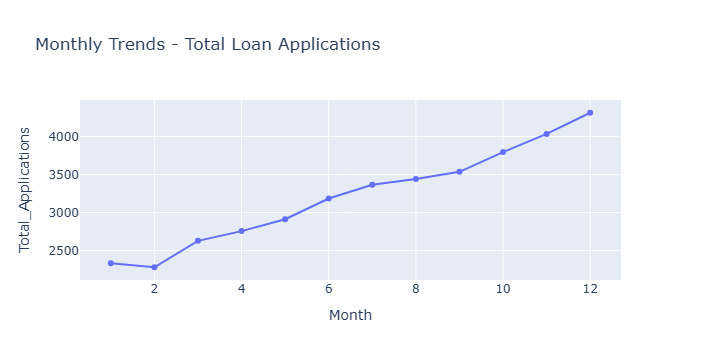

In [44]:
fig = px.line(
    monthly_data,
    x='Month_Number',
    y='Total_Applications',
    markers=True,
    title='Monthly Trends - Total Loan Applications'
)

fig.update_layout(
    xaxis_title='Month',
    yaxis_title='Total_Applications'
    )

fig.show()

#### Monthly Trends-Total Funded Amount

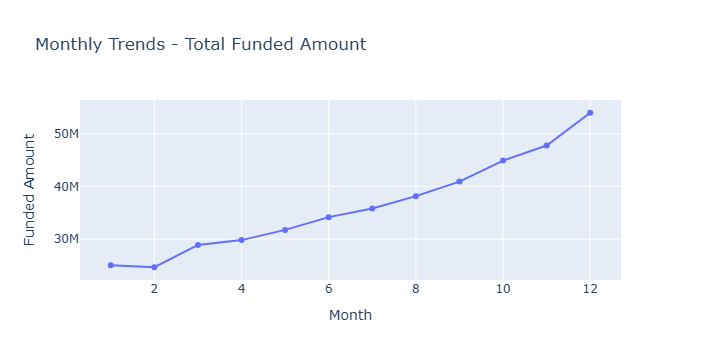

In [34]:
fig = px.line(
    monthly_data,
    x='Month_Number',
    y='Total_Funded_Amount',                                
    markers=True,
    title='Monthly Trends - Total Funded Amount'
)

fig.update_layout(
    xaxis_title='Month',
    yaxis_title='Funded Amount'
)

fig.show()

#### Monthly Trends-Total Amount Received 

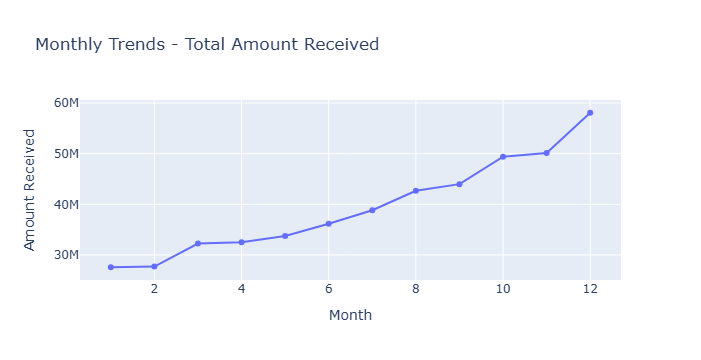

In [33]:
fig = px.line(
    monthly_data,
    x='Month_Number',
    y='Total_Amount_Received',
    markers=True,
    title='Monthly Trends - Total Amount Received'
)

fig.update_layout(
    xaxis_title='Month',
    yaxis_title='Amount Received'
)

fig.show()

## Regional Analysis by State

In [34]:
state_data = df.groupby('address_state').agg(
    Total_Applications=('id', 'count'),
    Total_Funded_Amount=('loan_amount', 'sum'),
    Total_Amount_Received=('total_payment', 'sum')
).reset_index()


,address_state,Total_Applications,Total_Funded_Amount,Total_Amount_Received
0,AK,78,1031800,1108570
1,AL,432,4949225,5492272
2,AR,236,2529700,2777875
3,AZ,833,9206000,10041986
4,CA,6894,78484125,83901234
5,CO,770,8976000,9845810
6,CT,730,8435575,9357612
7,DC,214,2652350,2921854
8,DE,110,1138100,1269136
9,FL,2773,30046125,31601905


#### Applications by State

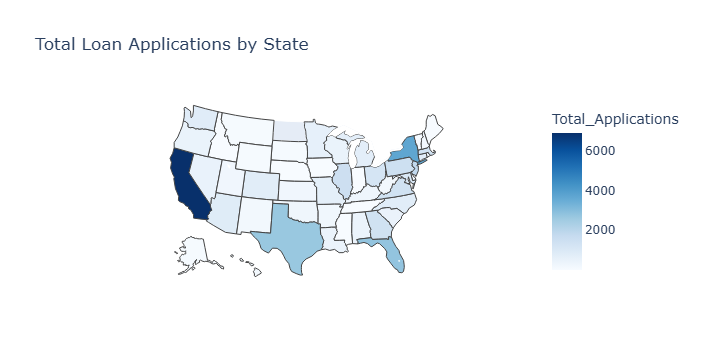

In [35]:
fig = px.choropleth(
    state_data,
    locations='address_state',
    locationmode='USA-states',
    color='Total_Applications',
    scope='usa',
    title='Total Loan Applications by State',
    color_continuous_scale='Blues'
)

fig.show()

#### Total Funded Amount by State

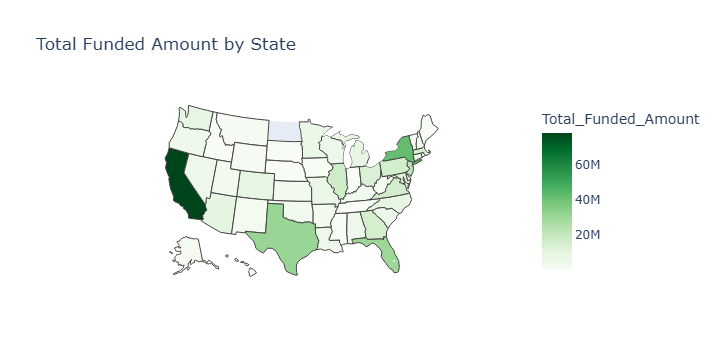

In [36]:
fig = px.choropleth(
    state_data,
    locations='address_state',
    locationmode='USA-states',
    color='Total_Funded_Amount',
    scope='usa',
    title='Total Funded Amount by State',
    color_continuous_scale='Greens'
)

fig.show()

#### Total Received Amount by State

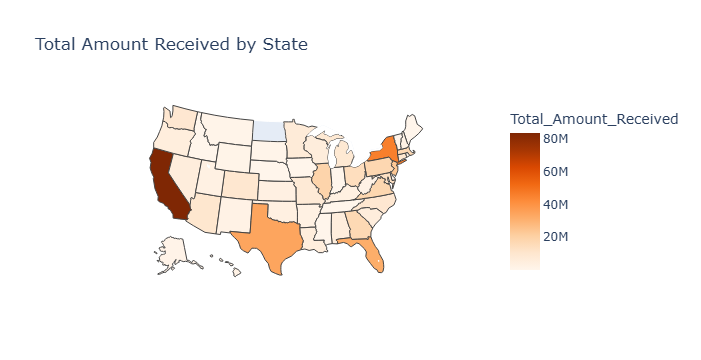

In [37]:
fig = px.choropleth(
    state_data,
    locations='address_state',
    locationmode='USA-states',
    color='Total_Amount_Received',
    scope='usa',
    title='Total Amount Received by State',
    color_continuous_scale='Oranges'
)

fig.show()

## Loan Term Analysis

In [46]:
term_data = df.groupby('term').agg(
    Total_Applications=('id', 'count'),
    Total_Funded_Amount=('loan_amount', 'sum'),
    Total_Amount_Received=('total_payment', 'sum')
).reset_index()

term_data

,term,Total_Applications,Total_Funded_Amount,Total_Amount_Received
0,36 months,28237,273041225,294709458
1,60 months,10339,162715850,178361475


#### Total Application by Term

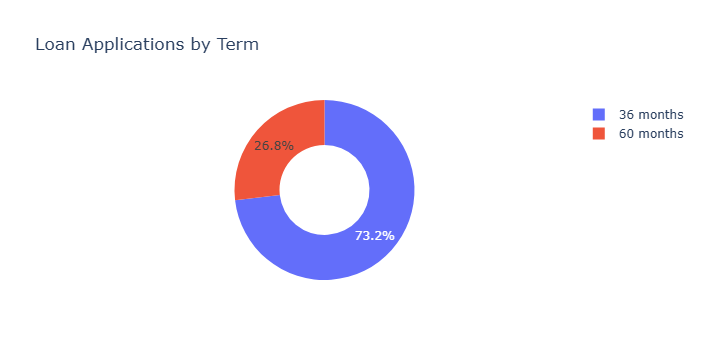

In [49]:
fig = px.pie(
    term_data,
    names='term',
    values='Total_Applications',
    hole=0.5,
    title='Loan Applications by Term'
)

fig.show()

#### Total Funded Amount by Term

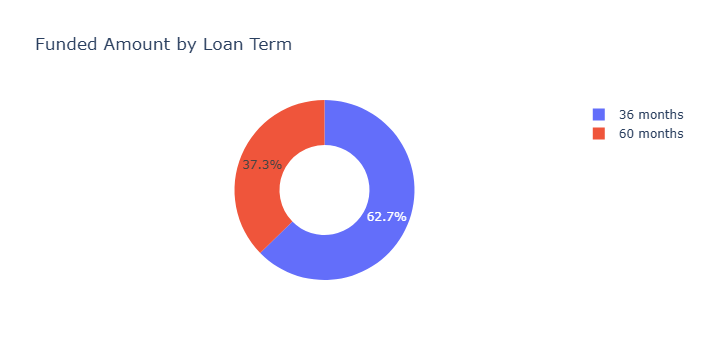

In [41]:
fig = px.pie(
    term_data,
    names='term',
    values='Total_Funded_Amount',
    hole=0.5,
    title='Funded Amount by Loan Term'
)

fig.show()

#### Total Received Amount by Term 

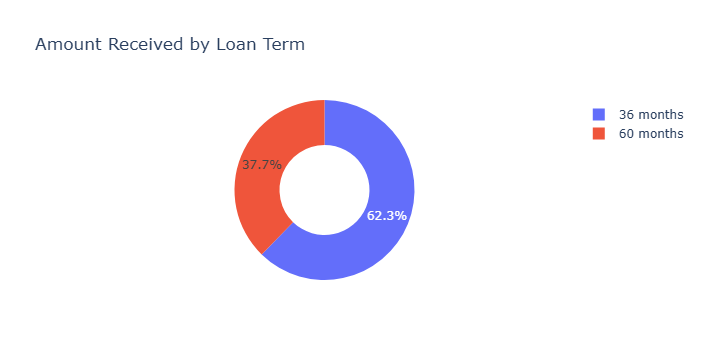

In [43]:
fig = px.pie(
    term_data,
    names='term',
    values='Total_Amount_Received',
    hole=0.5,
    title='Amount Received by Loan Term'
)

fig.show()

## Employee Length Analysis

In [44]:
emp_data = df.groupby('emp_length').agg(
    Total_Applications=('id', 'count'),
    Total_Funded_Amount=('loan_amount', 'sum'),
    Total_Amount_Received=('total_payment', 'sum')
).reset_index()

emp_data

,emp_length,Total_Applications,Total_Funded_Amount,Total_Amount_Received
0,1 year,3229,32883125,35498348
1,10+ years,8870,116115950,125871616
2,2 years,4382,44967975,49206961
3,3 years,4088,43937850,47551832
4,4 years,3428,37600375,40964850
5,5 years,3273,36973625,40397571
6,6 years,2228,25612650,27908658
7,7 years,1772,20811725,22584136
8,8 years,1476,17558950,19025777
9,9 years,1255,15084225,16516173


#### Total Applications by Employee Length

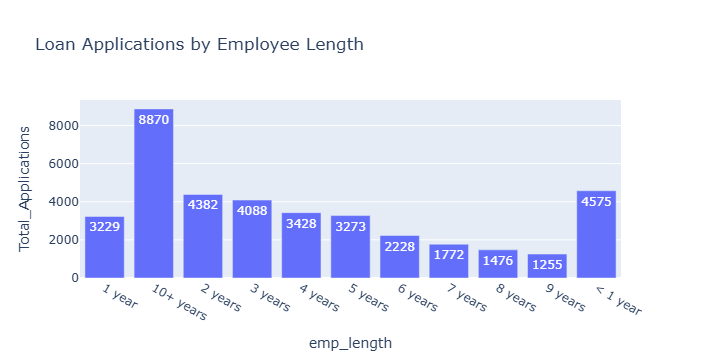

In [45]:
fig = px.bar(
    emp_data,
    x='emp_length',
    y='Total_Applications',
    title='Loan Applications by Employee Length',
    text_auto=True
)

fig.show()

#### Total Funded Amount by Employee Leength 

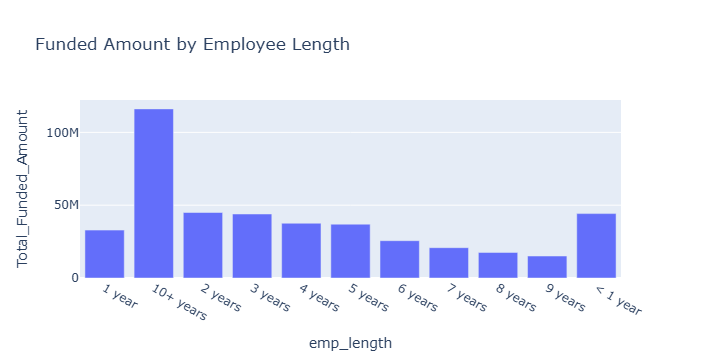

In [46]:
fig = px.bar(
    emp_data,
    x='emp_length',
    y='Total_Funded_Amount',
    title='Funded Amount by Employee Length'
)

fig.show()

#### Total Received Amount by Employee Length

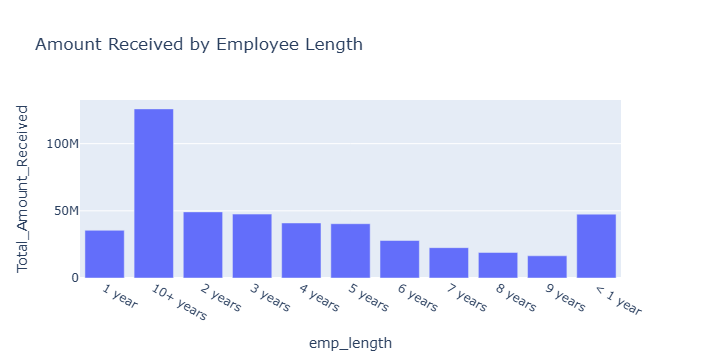

In [48]:
fig = px.bar(
    emp_data,
    x='emp_length',
    y='Total_Amount_Received',
    title='Amount Received by Employee Length'
)

fig.show()

## Loan Purpose Breakdown

In [52]:
purpose_data = df.groupby('purpose').agg(
    Total_Applications=('id', 'count'),
    Total_Funded_Amount=('loan_amount', 'sum'),
    Total_Amount_Received=('total_payment', 'sum')
).reset_index()

purpose_data

,purpose,Total_Applications,Total_Funded_Amount,Total_Amount_Received
0,Debt consolidation,18214,232459675,253801871
1,car,1497,10223575,11324914
2,credit card,4998,58885175,65214084
3,educational,315,2161650,2248380
4,home improvement,2876,33350775,36380930
5,house,366,4824925,5185538
6,major purchase,2110,17251600,18676927
7,medical,667,5533225,5851372
8,moving,559,3748125,3999899
9,other,3824,31155750,33289676


#### Total Loan Apllications by Purpose

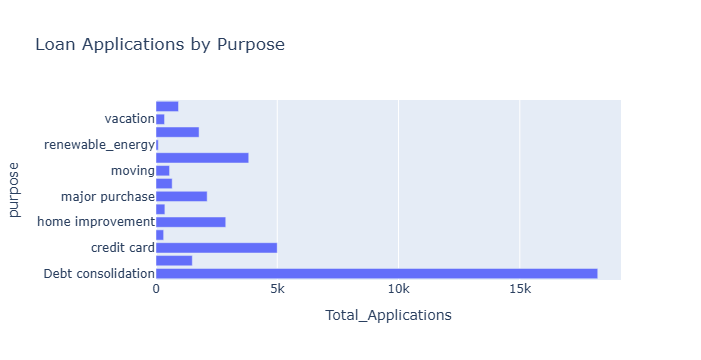

In [55]:
fig = px.bar(
    purpose_data,
    x='Total_Applications',
    y='purpose',
    orientation='h',
    title='Loan Applications by Purpose'
)

fig.show()

#### Total Funded Amount by Purpose

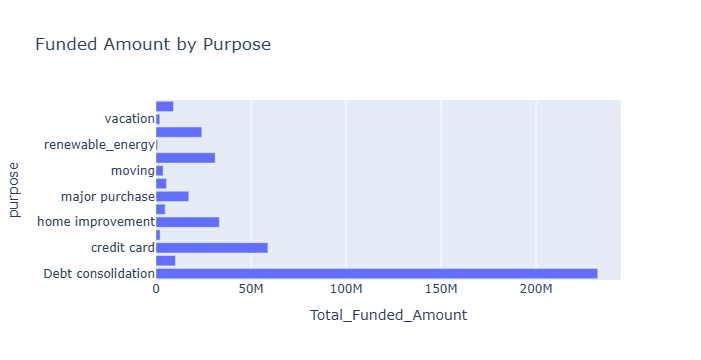

In [51]:
fig = px.bar(
    purpose_data,
    x='Total_Funded_Amount',
    y='purpose',
    orientation='h',
    title='Funded Amount by Purpose'
)

fig.show()

#### Total Amount Received by Purpose

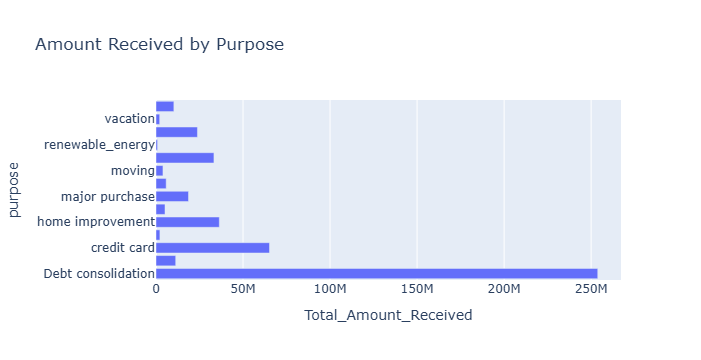

In [52]:
fig = px.bar(
    purpose_data,
    x='Total_Amount_Received',
    y='purpose',
    orientation='h',
    title='Amount Received by Purpose'
)

fig.show()

## Home Ownership Analysis

In [53]:
home_data = df.groupby('home_ownership').agg(
    Total_Applications=('id', 'count'),
    Total_Funded_Amount=('loan_amount', 'sum'),
    Total_Amount_Received=('total_payment', 'sum')
).reset_index()

home_data

,home_ownership,Total_Applications,Total_Funded_Amount,Total_Amount_Received
0,MORTGAGE,17198,219329150,238474438
1,NONE,3,16800,19053
2,OTHER,98,1044975,1025257
3,OWN,2838,29597675,31729129
4,RENT,18439,185768475,201823056


#### Total Loan Application by Home Owernship

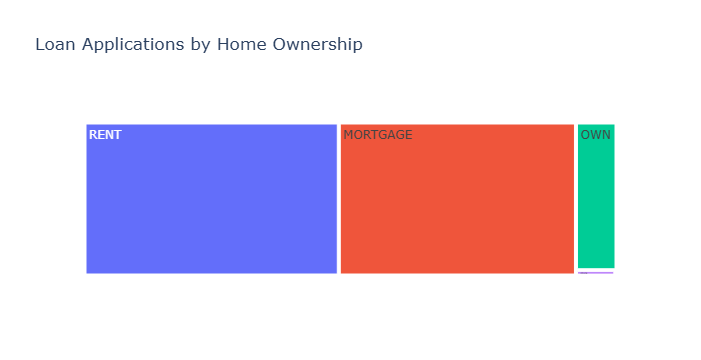

In [54]:
fig = px.treemap(
    home_data,
    path=['home_ownership'],
    values='Total_Applications',
    title='Loan Applications by Home Ownership'
)

fig.show()

#### Total Funded Amount by Home Owernship

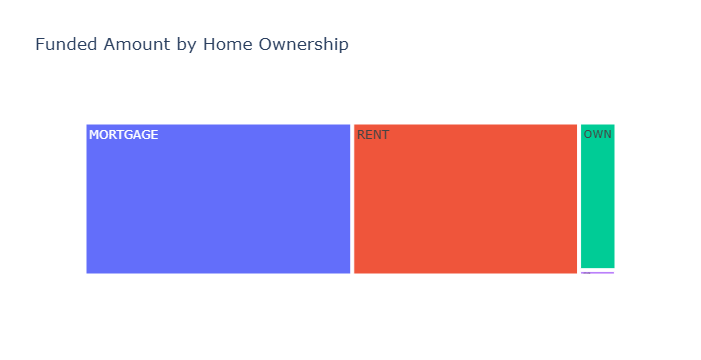

In [55]:
fig = px.treemap(
    home_data,
    path=['home_ownership'],
    values='Total_Funded_Amount',
    title='Funded Amount by Home Ownership'
)

fig.show()

#### Total Received Amount by Home Owernship

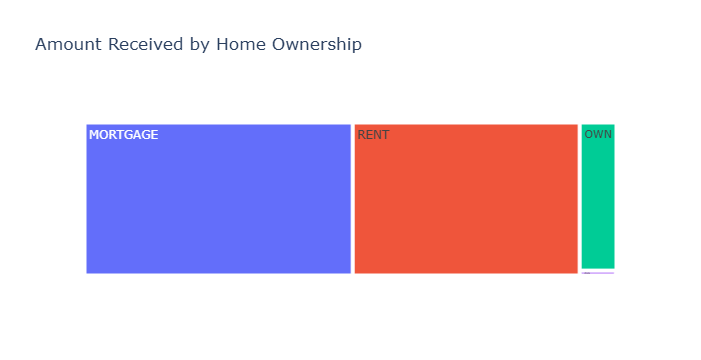

In [56]:
fig = px.treemap(
    home_data,
    path=['home_ownership'],
    values='Total_Amount_Received',
    title='Amount Received by Home Ownership'
)

fig.show()